# Обучение классификатора мата

Модель: **TF-IDF по символьным n-граммам + логистическая регрессия** (scikit-learn).

Почему она:
- мат часто пишут с ошибками, масками и латиницей (`пиздес`, `п*здец`, `pizdes`, `қотақ/котак`) — символьные n-граммы ловят общие куски слов;
- неизвестное слово всё равно разбивается на знакомые куски (`котакбастарсындар` → `кот`, `ота`, `так`...);
- данных мало (4 021 в train) — простая линейная модель учится за секунды на CPU и не переобучается так сильно, как BERT;
- веса можно посмотреть и объяснить.

Нужны файлы: `kz_regex.py`, `data/train.csv`, `data/val.csv`, `data/test.csv`.

In [2]:
import json, platform, itertools
from pathlib import Path

import numpy as np, pandas as pd, sklearn, joblib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, f1_score

import kz_regex

SEED = 42
np.random.seed(SEED)
MODEL_DIR = Path("model"); MODEL_DIR.mkdir(exist_ok=True)
BLUE = "#2a78d6"

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "joblib": joblib.__version__}
versions

{'python': '3.13.18',
 'numpy': '2.4.6',
 'pandas': '2.2.3',
 'scikit-learn': '1.6.1',
 'joblib': '1.6.0'}

## 1. Данные

In [4]:
train = pd.read_csv("data/train.csv")
val = pd.read_csv("data/val.csv")
test = pd.read_csv("data/test.csv")
pd.DataFrame({s: [len(d), d.label.sum(), round(d.label.mean(), 3)] for s, d in
              [("train", train), ("val", val), ("test", test)]}, index=["n", "мат", "доля мата"])

,train,val,test
n,4021.000,502.000,501.000
мат,1416.000,177.000,176.000
доля мата,0.352,0.353,0.351


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Как текст превращается во вход модели

1. `kz_regex.normalize` — правила, ничего не обучается:
   нижний регистр, `ё→е`, латинские двойники → кириллица в смешанных словах (`пиздeц` с латинской e), `@0 3 $ → а о з с`,
   `б.л.я → бля`, `бляяяя → бля`.
2. `TfidfVectorizer(analyzer="char_wb")` — режет каждое слово на символьные n-граммы с границами слова (` бл`, `бля`, `ля `).
   **Пунктуация** не удаляется: `*` внутри `п*здец` — часть n-граммы, это помогает ловить маски.
   Эмодзи и цифры тоже остаются как символы.
3. TF-IDF веса + L2-нормировка → разреженный вектор → логистическая регрессия → вероятность мата.

**Словарь n-грамм строится только на train** (`fit` на train, `transform` на val/test).
**Неизвестные слова:** нового слова нет в словаре, но его n-граммы обычно есть; n-граммы, которых не было в train, просто игнорируются.
**Длинные комментарии:** обрезки нет, текст любой длины → вектор одной размерности. Минус: в длинном тексте одно плохое слово «размывается» нормировкой (см. разбор ошибок).

In [6]:
for t in ["Пиздес ойын екен!!!", "бл*ть зайбал", "ПИЗДEЦ (лат. E)", "бляяяяя", "Котакбастар 😡"]:
    print(f"{t!r:25} -> {kz_regex.normalize(t)!r}")
v = TfidfVectorizer(preprocessor=kz_regex.normalize, analyzer="char_wb", ngram_range=(1, 4)).fit(["бл*ть"])
print(v.get_feature_names_out())

'Пиздес ойын екен!!!'     -> 'пиздес ойын екен!'
'бл*ть зайбал'            -> 'бл*ть зайбал'
'ПИЗДEЦ (лат. E)'         -> 'пиздец (лат. e)'
'бляяяяя'                 -> 'бля'
'Котакбастар 😡'           -> 'котакбастар 😡'
[' ' ' б' ' бл' ' бл*' '*' '*т' '*ть' '*ть ' 'б' 'бл' 'бл*' 'бл*т' 'л'
 'л*' 'л*т' 'л*ть' 'т' 'ть' 'ть ' 'ь' 'ь ']


## 3. Подбор настроек на val
Сетка: длина n-грамм × сила регуляризации `C` × веса классов. `min_df=2` (n-грамма должна встретиться хотя бы в 2 текстах train).
Для каждой модели подбираем порог на val; выбираем модель с лучшим F1 на val.

In [7]:
def make_model(ngram, C, cw):
    return Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=kz_regex.normalize, analyzer="char_wb",
                                  ngram_range=ngram, min_df=2, sublinear_tf=True)),
        ("clf", LogisticRegression(C=C, class_weight=cw, max_iter=3000, random_state=SEED)),
    ])

THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.05), 2)
rows = []
for ngram, C, cw in itertools.product([(1, 3), (1, 4), (1, 5)], [10, 30, 100], [None, "balanced"]):
    m = make_model(ngram, C, cw).fit(train.text, train.label)
    p = m.predict_proba(val.text)[:, 1]
    f1s = [f1_score(val.label, p >= t) for t in THRESHOLDS]
    i = int(np.argmax(f1s))
    rows.append({"ngram": ngram, "C": C, "class_weight": cw or "none",
                 "val_f1@0.5": round(f1_score(val.label, p >= 0.5), 4),
                 "val_f1_best": round(f1s[i], 4), "threshold": THRESHOLDS[i]})
grid = pd.DataFrame(rows).sort_values(["val_f1_best", "val_f1@0.5"], ascending=False).reset_index(drop=True)
grid.head(8)

,ngram,C,class_weight,val_f1@0.5,val_f1_best,threshold
0,"(1, 4)",100,none,0.9565,0.9659,0.30
1,"(1, 4)",30,none,0.9563,0.9657,0.35
2,"(1, 4)",100,balanced,0.9598,0.9632,0.35
3,"(1, 5)",30,none,0.9471,0.9632,0.35
4,"(1, 4)",30,balanced,0.9538,0.9630,0.40
5,"(1, 5)",100,balanced,0.9568,0.9600,0.40
6,"(1, 5)",100,none,0.9507,0.9600,0.30
7,"(1, 5)",10,none,0.9384,0.9573,0.35


In [8]:
best = grid.iloc[0]
cfg = {"ngram_range": list(best.ngram), "C": float(best.C),
       "class_weight": None if best.class_weight == "none" else best.class_weight}
cfg

{'ngram_range': [1, 4], 'C': 100.0, 'class_weight': None}

## 4. Обучаем выбранную модель на train и выбираем порог на val

порог: 0.3 | F1 на val: 0.9659 | признаков: 20595


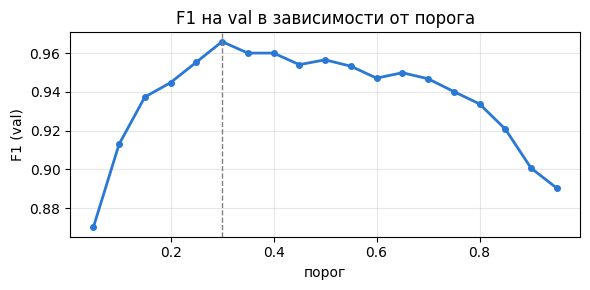

In [9]:
model = make_model(tuple(cfg["ngram_range"]), cfg["C"], cfg["class_weight"]).fit(train.text, train.label)
p_val = model.predict_proba(val.text)[:, 1]
f1s = [f1_score(val.label, p_val >= t) for t in THRESHOLDS]
THRESHOLD = float(THRESHOLDS[int(np.argmax(f1s))])
print("порог:", THRESHOLD, "| F1 на val:", round(max(f1s), 4), "| признаков:", len(model[0].vocabulary_))

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(THRESHOLDS, f1s, color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(THRESHOLD, color="gray", ls="--", lw=1)
ax.set_xlabel("порог"); ax.set_ylabel("F1 (val)"); ax.set_title("F1 на val в зависимости от порога")
ax.grid(alpha=.3); plt.tight_layout(); plt.show()

Порог выбран по максимуму F1 на val. Он ниже 0.5: при 0.3 на val меньше пропусков мата, а лишних срабатываний почти не добавляется.

## 5. Сохраняем модель и всё для инференса
`model/profanity_model.joblib` — весь Pipeline (нормализация + TF-IDF словарь + логрегрессия).
`model/config.json` — порог, настройки, seed, версии библиотек. Для загрузки рядом должен лежать `kz_regex.py`.

In [10]:
joblib.dump(model, MODEL_DIR / "profanity_model.joblib")
config = {
    "model": "TF-IDF char_wb n-grams + LogisticRegression",
    "preprocessing": "kz_regex.normalize (lowercase, ё->е, latin look-alikes->cyrillic, leet, joined dotted letters, collapsed repeats)",
    "tfidf": {"analyzer": "char_wb", "ngram_range": cfg["ngram_range"], "min_df": 2, "sublinear_tf": True},
    "logreg": {"C": cfg["C"], "class_weight": cfg["class_weight"], "max_iter": 3000, "solver": "lbfgs"},
    "threshold": THRESHOLD, "seed": SEED,
    "train_size": len(train), "val_f1": round(max(f1s), 4), "n_features": len(model[0].vocabulary_),
    "versions": versions,
}
(MODEL_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2))
print(json.dumps(config, ensure_ascii=False, indent=2))

{
  "model": "TF-IDF char_wb n-grams + LogisticRegression",
  "preprocessing": "kz_regex.normalize (lowercase, ё->е, latin look-alikes->cyrillic, leet, joined dotted letters, collapsed repeats)",
  "tfidf": {
    "analyzer": "char_wb",
    "ngram_range": [
      1,
      4
    ],
    "min_df": 2,
    "sublinear_tf": true
  },
  "logreg": {
    "C": 100.0,
    "class_weight": null,
    "max_iter": 3000,
    "solver": "lbfgs"
  },
  "threshold": 0.3,
  "seed": 42,
  "train_size": 4021,
  "val_f1": 0.9659,
  "n_features": 20595,
  "versions": {
    "python": "3.13.18",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "joblib": "1.6.0"
  }
}


Какие n-граммы модель считает самыми «матерными» и самыми «чистыми»:

In [11]:
names = model[0].get_feature_names_out(); w = model[1].coef_[0]
top = pd.DataFrame({"мат (+)": names[np.argsort(w)[-20:][::-1]], "вес+": np.sort(w)[-20:][::-1].round(1),
                    "не мат (−)": names[np.argsort(w)[:20]], "вес−": np.sort(w)[:20].round(1)})
top

,мат (+),вес+,не мат (−),вес−
0,ота,18.1,,-6.7
1,бл,14.1,от,-4.8
2,бл,14.1,р,-4.5
3,бля,13.7,ге,-4.5
4,бля,13.5,оқта,-4.4
5,қот,13.1,ба,-3.7
6,ху,13.0,ы,-3.7
7,қот,12.9,та,-3.7
8,қота,12.9,жоқ,-3.6
9,ля,12.9,❤,-3.6


## 6. Оценка на test — один раз
Все настройки и порог выбраны выше по val; test здесь используется впервые.

In [12]:
p_test = model.predict_proba(test.text)[:, 1]
test["p"] = p_test.round(3)
test["pred"] = (p_test >= THRESHOLD).astype(int)

P, R, F, _ = precision_recall_fscore_support(test.label, test.pred, average="binary")
cm = confusion_matrix(test.label, test.pred)
print(f"test: n={len(test)} (мат={test.label.sum()})")
print(f"класс «мат»: precision={P:.3f}  recall={R:.3f}  F1={F:.3f}")
pd.DataFrame(cm, index=["факт: не мат", "факт: мат"], columns=["прогноз: не мат", "прогноз: мат"])

test: n=501 (мат=176)
класс «мат»: precision=0.926  recall=0.926  F1=0.926


,прогноз: не мат,прогноз: мат
факт: не мат,312,13
факт: мат,13,163


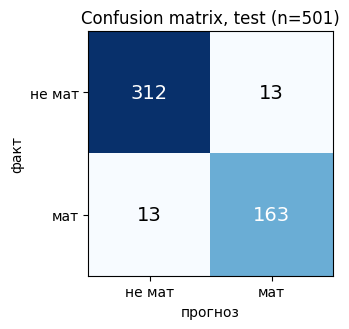

In [13]:
fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["не мат", "мат"]); ax.set_yticks([0, 1], ["не мат", "мат"])
ax.set_xlabel("прогноз"); ax.set_ylabel("факт"); ax.set_title(f"Confusion matrix, test (n={len(test)})")
plt.tight_layout(); plt.show()

По источникам и в сравнении с regex (v1 — честный baseline):

In [14]:
def prf(y, yp):
    p, r, f, _ = precision_recall_fscore_support(y, yp, average="binary", zero_division=0)
    return round(p, 3), round(r, 3), round(f, 3)

rows = []
for name, part in [("весь test", test), ("KazSAnDRA", test[test.source == "kazsandra"]), ("YouTube", test[test.source == "youtube"])]:
    rows.append([name, len(part), part.label.sum(), "модель", *prf(part.label, part.pred)])
    rows.append([name, len(part), part.label.sum(), "regex v1", *prf(part.label, part.text.map(lambda t: kz_regex.is_profane(t, 1)))])
pd.DataFrame(rows, columns=["часть", "n", "мат", "метод", "P", "R", "F1"])

,часть,n,мат,метод,P,R,F1
0,весь test,501,176,модель,0.926,0.926,0.926
1,весь test,501,176,regex v1,0.982,0.920,0.950
2,KazSAnDRA,425,166,модель,0.929,0.940,0.934
3,KazSAnDRA,425,166,regex v1,0.994,0.946,0.969
4,YouTube,76,10,модель,0.875,0.700,0.778
5,YouTube,76,10,regex v1,0.714,0.500,0.588


Длинные комментарии:

In [15]:
test["len_bin"] = pd.cut(test.text.str.len(), [0, 50, 150, 10_000], labels=["≤50", "51–150", ">150"])
test.groupby("len_bin", observed=True).apply(
    lambda d: pd.Series({"n": len(d), "мат": d.label.sum(), "FN": ((d.label == 1) & (d.pred == 0)).sum(),
                         "FP": ((d.label == 0) & (d.pred == 1)).sum(), "F1": round(f1_score(d.label, d.pred), 3)}))

/tmp/ipykernel_2294/3680397847.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test.groupby("len_bin", observed=True).apply(


,n,мат,FN,FP,F1
len_bin,,,,,
≤50,300.0,111.0,6.0,2.0,0.963
51–150,157.0,49.0,3.0,7.0,0.902
>150,44.0,16.0,4.0,4.0,0.750


## 7. Ошибки

In [16]:
pd.set_option("display.max_colwidth", 140)
print("ЛОЖНЫЕ СРАБАТЫВАНИЯ (FP): модель сказала «мат», а мата нет")
display(test[(test.pred == 1) & (test.label == 0)][["id", "p", "text"]])
print("ПРОПУСКИ (FN): мат есть, модель не заметила")
display(test[(test.pred == 0) & (test.label == 1)][["id", "p", "text"]])

ЛОЖНЫЕ СРАБАТЫВАНИЯ (FP): модель сказала «мат», а мата нет


,id,p,text
23,kz00292,0.384,Нащар казакща олендер деп алп кайдагы жок орстар щетелдердің əндері журго Казакща дедіңдерма казакща олен щгарың
83,kz00864,0.446,Негізі ютоб го жақ сырақ өйткені одан əр нəрсе тартып аласын ал мынада бартылмайды
98,kz01003,0.566,Татақ
132,kz01363,0.885,"Скоро у вас таких оценок будет много, как в choco.life прям🥰. Не деген масқара мнау? Қазақ тілін мазақ қылып тұрсындар ма? Ешнәрсе қазақ..."
143,kz01498,0.443,Реклама 100 рет боладығо несі бұның ойын 💩😡😡😡😡😡😡😡😡😡😡😡😡😡😡😡😡😡😡😡😡😡 мың реклама болдығо скатина ойын емес ХАКЕР🍌
172,kz01812,0.788,1)18+ балағат сөздерге жол берілген 2)адамды жынды қылып жіберген 3)барлық адам түсіреді неге не қызық бар 4)түсірген адам ешакбас 5)збл...
210,kz02227,0.598,мал топас мегабайтымды алды ешак мал жынды
225,kz02344,0.313,Маган бугин 10000 тенге аударган онын 80500 Гана келди калганы жок бастысы мен жол ережесин бузды тыныштыкты бузды деп айып тагып 15000 ...
226,kz02346,0.559,Разработчиктер п а ш о л н а х у интернет вобше ұстамай и тағы тарифтеріңді 30 күн емес 29күн ғана қолдана аласың
259,kz02749,0.372,Потом ол уже қуып қалған ом біреудін атына біреу кіреді. 2-3сағат сайын логин парол сұрайд сосын бір точка или бір орында бос калса кате...


ПРОПУСКИ (FN): мат есть, модель не заметила


,id,p,text
55,kz00551,0.060,Апай сәлеметсіз бе Боқ
94,kz00961,0.067,Стасам Амдарынызды шыгарам
115,kz01190,0.067,В п*зду бұндай приложение банктарыңның бір жерін с*гейін..жылына бір рет распродажа ұйымдастырамыз деп шамаларың келмей отырсыңдар..сол ...
119,kz01222,0.137,Ешкім алмасын бұл банктен күні не 300 теңге ден косыла телефон алгам пидараз банк екен алуға кеңес бермеймін.👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎👎...
131,kz01358,0.044,Өте нашар.Не мазақ фотоға түсіріп бетіңызді шеңбер ішіне апарыңыз дейді апарсаң сол күйі тұрасың жалғасы жоқ.Өте төмен бағаламаймын еңбе...
180,kz01925,0.079,Koti boq til istemet
264,kz02824,0.115,зайбал неге тартылмай жатыр
274,kz02929,0.112,Қолдарынан боқта келмейді есалаңдар. Паспорт қарай алмай отырық. Қолдарыннан келмесе беріңдер келетін адамдарға сапбастар. Жабысып аласы...
288,kz03016,0.171,"Таңғажайып пернетақта. Мүмкін болса, күш қуаттарың жетсе, Қайсарларың жетсе, батыл болсаңдар, ЛАТИННИЦАНЫ ""нахуй"" алып тастаңдаршы. Құда..."
398,kz03941,0.018,👎👎👎👎👎👎👎👎👎боққа керегі жоқ сайт дұрыс жасамайды


In [17]:
# пограничные: вероятность рядом с порогом
test.assign(d=(test.p - THRESHOLD).abs()).sort_values("d").head(8)[["id", "label", "p", "text"]]

,id,label,p,text
183,kz01934,0,0.299,Не истеп койгансындар Кире алмайм Бир ай болды срок истекло деп
150,kz01537,1,0.309,Жалеп арен тартым брак қызык ойын екен
225,kz02344,0,0.313,Маган бугин 10000 тенге аударган онын 80500 Гана келди калганы жок бастысы мен жол ережесин бузды тыныштыкты бузды деп айып тагып 15000 ...
383,kz03858,1,0.325,boq qoi mynau
260,kz02750,1,0.329,Мә пездес екен ема остыр қанда тартым
205,kz02130,0,0.253,Ихтияр бірбале боқтанбай сөйле!👍👍👍👍👍
11,kz00097,0,0.237,Надан және мал ойын
259,kz02749,0,0.372,Потом ол уже қуып қалған ом біреудін атына біреу кіреді. 2-3сағат сайын логин парол сұрайд сосын бір точка или бір орында бос калса кате...


## Разбор результатов

**Что значат ошибки в этой задаче**
- **False positive (FP)** — чистый отзыв помечен как мат. На площадке такой отзыв скроют или отправят на проверку. Чаще всего это злой, но честный негативный отзыв («мал», «скатина», «ешак») — его скрытие выглядит как цензура жалоб покупателей.
- **False negative (FN)** — мат пропущен и опубликован. Его увидят все, включая детей; нарушаются правила площадки.

Для **автоматического удаления** хуже FP: удалять честные жалобы нельзя. Для **отправки модератору** хуже FN: лишняя проверка дешевле, чем опубликованный мат.
Поэтому на практике нужны два порога: `p ≥ 0.9` — скрыть сразу, `0.3 ≤ p < 0.9` — к модератору, `p < 0.3` — публиковать.

**Модель vs regex.** На KazSAnDRA regex v1 чуть лучше модели (F1 0.969 против 0.934). Это ожидаемо: метки KazSAnDRA получены из regex v1 + проверки, поэтому словарь regex и метки сильно совпадают. На YouTube, где ни модель, ни regex v1 не видели данных при разработке, модель лучше: F1 0.778 против 0.588. То есть модель обобщает лучше словаря, но в YouTube-test всего 10 примеров с матом — цифры шумные.

**Разбор ошибок (примеры из test)**

1. **Мат в длинном тексте «растворяется».** `kz01358` — длинная жалоба на налоговую, мат одно последнее слово («сіктіңдер»), p = 0.04. `kz03016` — «нахуй» в кавычках внутри длинного отзыва, p = 0.17. `kz01222` — «пидараз» и 38 эмодзи 👎, p = 0.14.
   *Причина:* TF-IDF вектор нормируется по длине, одна плохая n-грамма тонет среди сотен нейтральных. По длине: F1 = 0.963 для текстов ≤ 50 символов и 0.750 для > 150.
   *Проверено на val:* оценивать текст кусками по 8 слов и брать максимум — recall вырос (0.96 → 0.97), но precision упал (0.97 → 0.93), F1 хуже. Нужен не просто max, а обучение на коротких кусках.

2. **Маски.** `kz01190` — «п*зду», «с*гейін», «к*ттерің» — три маскированных слова, p = 0.07. Звёздочка разрывает знакомые n-граммы, а маскированных примеров в train мало.
   *Улучшение:* аугментация — в train случайно заменять 1–2 буквы внутри матерных слов на `*`.

3. **Похожие куски у нормальных слов.** Символьные n-граммы видят буквы, а не смысл:
   `kz03770` — «көтердіде», «котермеді» (взяла трубку) дают n-граммы `көт`, `кот`;
   `yt00439` — «есігі блогқа» (дверь блокируется): `сіг` как в «сігейін», ` бл` как в «бля»;
   `kz01003` — «Татақ» (эвфемизм) — `тақ` как в «қотақ»;
   `kz00292` — автор пишет «щ» вместо «ш» («Нащар казакща»), а `щ` модель связала с сокращением «щщс».

4. **Грубость ≠ мат.** `kz02227` «мал топас … ешак мал жынды», `kz03430` «малдар», `kz01498` «скатина» — оскорбления без мата, но в train они часто стоят рядом с матом, и модель выучила эту связь.

5. **Редкие формы.** `yt00578` «жәлеп», `yt00324` «Далбан», `kz00961` «Амдарынызды», `kz02824` «зайбал» — в train таких слов единицы, p < 0.15.

6. **Ошибки в разметке, найденные моделью.** `kz02346` «п а ш о л н а х у» (мат через пробелы) и `kz01812` («зблар», «көтті қыста») размечены как 0, но это мат — regex не ловит буквы через пробел, а при выборочной проверке они не попали в выборку. Модель здесь права. Метрики оставлены как есть (test размечен до обучения), но с исправленными метками precision был бы 165/176 = 0.94.

7. **Непонятная уверенность.** `kz01363` — эмоциональная жалоба на русификацию (русский + казахский, в конце «###», похоже, слово скрыл сам сайт), p = 0.89. Ни одна n-грамма не выделяется: вероятность сложилась из множества слабых признаков. Такие случаи и нужно отдавать человеку.

**Что улучшить в первую очередь**
1. Исправить найденные ошибки разметки и добавить примеры редких форм и масок (аугментация звёздочками).
2. Для длинных отзывов — обучать модель на предложениях (разбить train на куски) и брать максимум по кускам.
3. В продакшене — два порога и ручная проверка «серой зоны»; regex v2 как список однозначных корней, которые всегда отправляются модератору.


## 8. Как использовать сохранённую модель

In [18]:
clf = joblib.load("model/profanity_model.joblib")
thr = json.load(open("model/config.json"))["threshold"]

def predict(texts):
    p = clf.predict_proba(texts)[:, 1]
    return [(t, round(float(x), 3), int(x >= thr)) for t, x in zip(texts, p)]

predict(["Сапасы өте нашар, ақшамды қайтарыңыз", "Пиздес ойын екен", "қотақбас мал",
         "Керемет телефон, рахмет!", "п*здец қымбат", "Блин жеткізу кешікті"])

[('Сапасы өте нашар, ақшамды қайтарыңыз', 0.0, 0),
 ('Пиздес ойын екен', 1.0, 1),
 ('қотақбас мал', 1.0, 1),
 ('Керемет телефон, рахмет!', 0.0, 0),
 ('п*здец қымбат', 0.771, 1),
 ('Блин жеткізу кешікті', 0.006, 0)]